# Lab 2: Supervised learning I (regression, classification, and the workflow)

Two regression examples, two classification examples, and a saved model at the end: fit
pipelines, validate in date order where time matters, tune thresholds and hyperparameters,
test once, and save the models.

This notebook follows the Lab 2 handout: Parts A to E, the heart disease *Try it yourself*,
the decision memo and the questions, plus the Chapter 4 questions at the end. The code saves
every chart and table to `results/lab02/` and the models to `models/`.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Notebooks live in all_experiments/, so the course folder is one level up.
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)
RESULTS = PROJECT_ROOT / "results" / "lab02"
RESULTS.mkdir(parents=True, exist_ok=True)
summary = {}  # headline numbers, saved to results/lab02/summary.json at the end

# Dark charts to match the README. Cyan and orange pass a colour-blindness check on this background.
CYAN, ORANGE, INK, MUTED, GRID = "#2f9fd6", "#d86f2e", "#e6edf3", "#8b949e", "#30363d"
plt.rcParams.update({
    "figure.facecolor": "#0d1117", "axes.facecolor": "#0d1117", "savefig.facecolor": "#0d1117",
    "text.color": INK, "axes.labelcolor": "#c9d1d9", "axes.edgecolor": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 1.8, "figure.dpi": 110,
    "axes.prop_cycle": matplotlib.cycler(color=[CYAN, ORANGE]),
})
HEAT = LinearSegmentedColormap.from_list("heat", ["#161b22", "#6cbfe8"])  # one hue: dark is small


def save_plot(filename):
    plt.savefig(RESULTS / filename, dpi=170, bbox_inches="tight")
    plt.show()

One helper handles the preprocessing for every model below: median imputation and scaling
for numbers, most-frequent imputation and one-hot encoding for categories.

In [2]:
def make_preprocess(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ])

## Part A: Regression, ordinary least squares versus ridge

Predict insurance `charges`. OLS and ridge get the same features and the same split. MAE is
the average error in dollars, RMSE weighs large misses more, and R² compares the squared
error with always predicting the mean.

In [3]:
insurance = pd.read_csv(DATA / "medical_cost_personal_dataset.csv")
display(insurance.head())

X = insurance.drop(columns="charges")
y = insurance["charges"]
num_cols = ["age", "bmi", "children"]
cat_cols = ["sex", "smoker", "region"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
fitted = {}
predictions = {}
insurance_scores = {}

for name, estimator in {
    "linear regression": LinearRegression(),
    "ridge": Ridge(alpha=10.0),
}.items():
    model = Pipeline([("preprocess", make_preprocess(num_cols, cat_cols)), ("model", estimator)])
    model.fit(X_train, y_train)
    fitted[name] = model
    predictions[name] = model.predict(X_valid)
    pred = predictions[name]
    insurance_scores[name] = {
        "MAE": mean_absolute_error(y_valid, pred),
        "RMSE": np.sqrt(mean_squared_error(y_valid, pred)),
        "R2": r2_score(y_valid, pred),
    }

scores_table = pd.DataFrame(insurance_scores).T
scores_table.to_csv(RESULTS / "insurance_metrics.csv", index_label="model")
display(scores_table.round({"MAE": 2, "RMSE": 2, "R2": 3}))
summary["insurance"] = scores_table.round(4).to_dict("index")

,MAE,RMSE,R2
linear regression,4181.19,5796.28,0.784
ridge,4238.82,5821.59,0.782


Coefficients give conditional changes in the prediction. The numerical inputs are
standardized, so their coefficients are the change for one standard deviation.

,coefficient
cat__smoker_no,-11825.56
cat__region_southwest,-350.21
cat__region_southeast,-198.28
cat__sex_male,-9.30
cat__sex_female,9.30
cat__region_northwest,88.91
cat__region_northeast,459.59
num__children,516.89
num__bmi,2036.23
num__age,3614.98


smoker_yes minus smoker_no: $23,651.13


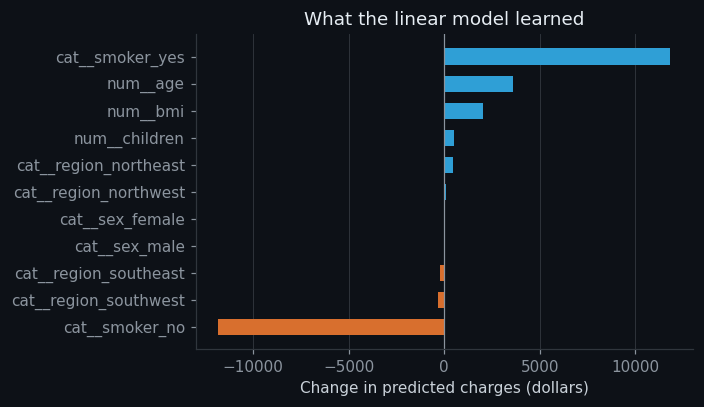

In [5]:
linear = fitted["linear regression"]
names = linear.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(linear.named_steps["model"].coef_, index=names).sort_values()
display(coefs.round(2).to_frame("coefficient"))
smoker_gap = coefs["cat__smoker_yes"] - coefs["cat__smoker_no"]
print(f"smoker_yes minus smoker_no: ${smoker_gap:,.2f}")
summary["smoker_gap"] = round(float(smoker_gap), 2)

plt.figure(figsize=(6.5, 3.8))
plt.barh(coefs.index, coefs.values, height=0.6, color=np.where(coefs.values >= 0, CYAN, ORANGE))
plt.axvline(0, color=MUTED, linewidth=0.8)
plt.xlabel("Change in predicted charges (dollars)")
plt.title("What the linear model learned")
plt.grid(axis="y", visible=False)
plt.tight_layout()
save_plot("insurance_coefficients.png")

**Observations.** OLS reaches a validation MAE of $4,181 (RMSE $5,796, R² 0.784). Ridge with
alpha=10 is a little worse on all three. The encoder keeps a column for each smoker level, so
the smoker effect is the gap between `smoker_yes` (+$11,826) and `smoker_no` (-$11,826):
$23,651, the "more than $20,000" in the handout. Age (+$3,615 per standard deviation) and BMI
(+$2,036) matter far more than region, where every coefficient stays under $500. These are
associations in this data, not causal effects.

Next, the ridge residuals. Structure left in them points to a pattern the model missed.

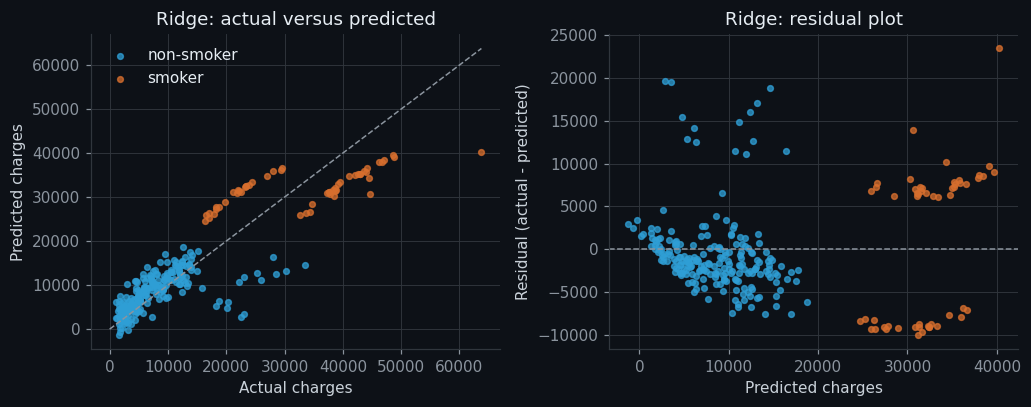

bmi,bmi < 30,bmi >= 30
smoker,,
no,7977.0,8843.0
yes,21363.0,41558.0


In [6]:
ridge_pred = predictions["ridge"]
residual = y_valid.to_numpy() - ridge_pred
is_smoker = (X_valid["smoker"] == "yes").to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for mask, label, color in [(~is_smoker, "non-smoker", CYAN), (is_smoker, "smoker", ORANGE)]:
    axes[0].scatter(y_valid[mask], ridge_pred[mask], s=14, alpha=0.75, color=color, label=label)
    axes[1].scatter(ridge_pred[mask], residual[mask], s=14, alpha=0.75, color=color, label=label)
axes[0].plot([0, y_valid.max()], [0, y_valid.max()], linestyle="--", color=MUTED, linewidth=1)
axes[0].set_xlabel("Actual charges")
axes[0].set_ylabel("Predicted charges")
axes[0].set_title("Ridge: actual versus predicted")
axes[0].legend()
axes[1].axhline(0, linestyle="--", color=MUTED, linewidth=1)
axes[1].set_xlabel("Predicted charges")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Ridge: residual plot")
plt.tight_layout()
save_plot("insurance_residuals.png")

# Average charges by smoker and BMI group, over all rows.
bmi_group = insurance["bmi"].ge(30).map({False: "bmi < 30", True: "bmi >= 30"})
display(insurance.pivot_table(index="smoker", columns=bmi_group, values="charges",
                              aggfunc="mean").round(0))

**Observations.** The residuals do not form a flat cloud. Smokers split into two bands: one
predicted about $9,000 too high, the other about $7,000 too low. The table shows why: smokers
with a BMI of 30 or more average $41,558 in charges against $21,363 for leaner smokers, while
for non-smokers BMI barely matters ($8,843 against $7,977). That is the smoker × BMI
interaction from the handout. The linear model adds the same smoker amount to everyone, so it
lands between the two groups, and ridge only shrinks coefficients, so it cannot add the
missing interaction either. A handful of non-smokers also cost $11,000 to $20,000 more than
predicted, and the six inputs give the model no way to see why.

## Part B: Regression on a time series, validate in date order

Two years of daily bike rentals. Sort by date and keep the last 20% for validation, so the
model never trains on days that come after the ones it is scored on.

In [7]:
bikes = pd.read_csv(DATA / "bike_sharing_dataset_day.csv")
bikes["dteday"] = pd.to_datetime(bikes["dteday"])
bikes = bikes.sort_values("dteday").reset_index(drop=True)

# cnt = casual + registered, so those two columns would leak the answer.
bike_cat = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]
bike_num = ["temp", "atemp", "hum", "windspeed"]
X_b = bikes[bike_cat + bike_num]
y_b = bikes["cnt"]

cut = int(len(bikes) * 0.80)
print("train:", bikes["dteday"].iloc[0].date(), "to", bikes["dteday"].iloc[cut - 1].date())
print("valid:", bikes["dteday"].iloc[cut].date(), "to", bikes["dteday"].iloc[-1].date())

train: 2011-01-01 to 2012-08-06
valid: 2012-08-07 to 2012-12-31


The calendar fields are one-hot encoded. The weather numbers go straight into the random
forest, which does not need scaled inputs.

daily MAE: 1040.4  (mean daily demand in validation: 5897.8 )
busiest training day: 8362  highest prediction: 7406
validation days underpredicted: 76%
average shortfall on the 10 busiest validation days: 1358


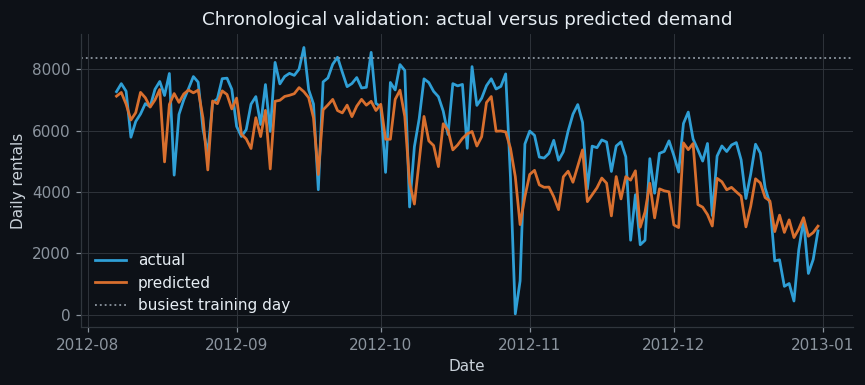

In [8]:
Xb_train, Xb_valid = X_b.iloc[:cut], X_b.iloc[cut:]
yb_train, yb_valid = y_b.iloc[:cut], y_b.iloc[cut:]
dates_valid = bikes["dteday"].iloc[cut:]

bike_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), bike_cat),
        ("num", "passthrough", bike_num),
    ])),
    ("model", RandomForestRegressor(
        n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1
    )),
])
bike_model.fit(Xb_train, yb_train)
bike_pred = bike_model.predict(Xb_valid)
daily_mae = mean_absolute_error(yb_valid, bike_pred)
print("daily MAE:", round(daily_mae, 1),
      " (mean daily demand in validation:", round(yb_valid.mean(), 1), ")")
print("busiest training day:", yb_train.max(), " highest prediction:", round(bike_pred.max()))
print(f"validation days underpredicted: {(yb_valid.to_numpy() > bike_pred).mean():.0%}")
busiest = np.argsort(yb_valid.to_numpy())[-10:]
print("average shortfall on the 10 busiest validation days:",
      round((yb_valid.to_numpy()[busiest] - bike_pred[busiest]).mean()))
summary["bike_daily"] = {"mae": round(daily_mae, 1), "validation_mean": round(yb_valid.mean(), 1)}

plt.figure(figsize=(8, 3.6))
plt.plot(dates_valid, yb_valid.to_numpy(), label="actual")
plt.plot(dates_valid, bike_pred, label="predicted")
plt.axhline(yb_train.max(), color=MUTED, linestyle=":", linewidth=1.2, label="busiest training day")
plt.xlabel("Date")
plt.ylabel("Daily rentals")
plt.title("Chronological validation: actual versus predicted demand")
plt.legend(loc="lower left")
plt.tight_layout()
save_plot("bike_daily_validation.png")

**Observations.** Training covers 1 January 2011 to 6 August 2012, and validation the rest of
2012. The daily MAE is 1,040 rentals, about 18% of an average validation day (5,898). The
forest follows the seasonal shape but runs low: it underpredicts 76% of validation days and
falls short by about 1,360 rentals on the 10 busiest. A forest predicts averages of training
days, so it can never go above the busiest day it has seen (8,362), and its highest
prediction is 7,406.

Repeat in date order on the 17,379 hourly rows, adding the hour `hr`, and plot one
validation week.

hourly MAE: 56.5  (mean hourly demand in validation: 248.8 )


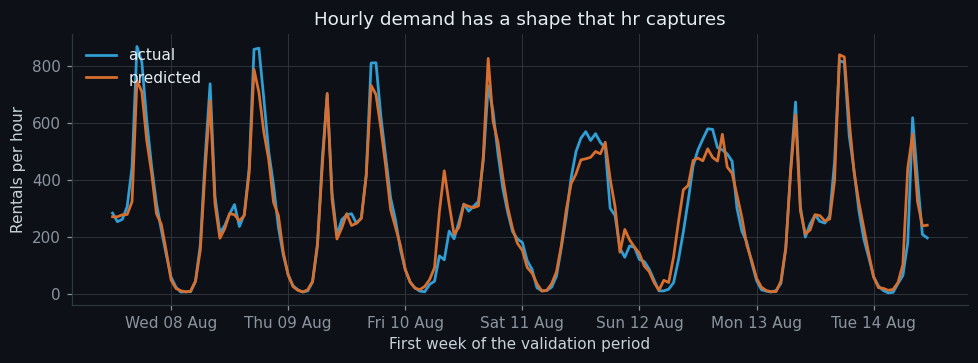

In [9]:
hourly = pd.read_csv(DATA / "bike_sharing_dataset_hour.csv")
hourly["dteday"] = pd.to_datetime(hourly["dteday"])
hourly = hourly.sort_values(["dteday", "hr"]).reset_index(drop=True)

hour_cat = bike_cat + ["hr"]
Xh = hourly[hour_cat + bike_num]
yh = hourly["cnt"]
cut_h = int(len(hourly) * 0.80)

hour_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), hour_cat),
        ("num", "passthrough", bike_num),
    ])),
    ("model", RandomForestRegressor(
        n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1
    )),
])
hour_model.fit(Xh.iloc[:cut_h], yh.iloc[:cut_h])
hour_pred = hour_model.predict(Xh.iloc[cut_h:])
hourly_mae = mean_absolute_error(yh.iloc[cut_h:], hour_pred)
print("hourly MAE:", round(hourly_mae, 1),
      " (mean hourly demand in validation:", round(yh.iloc[cut_h:].mean(), 1), ")")
summary["bike_hourly"] = {"mae": round(hourly_mae, 1),
                          "validation_mean": round(yh.iloc[cut_h:].mean(), 1)}

week = slice(0, 24 * 7)
stamps = (hourly["dteday"] + pd.to_timedelta(hourly["hr"], unit="h")).iloc[cut_h:].iloc[week]
plt.figure(figsize=(9, 3.4))
plt.plot(stamps, yh.iloc[cut_h:].to_numpy()[week], label="actual")
plt.plot(stamps, hour_pred[week], label="predicted")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
plt.xlabel("First week of the validation period")
plt.ylabel("Rentals per hour")
plt.title("Hourly demand has a shape that hr captures")
plt.legend(loc="upper left")
plt.tight_layout()
save_plot("bike_hourly_validation.png")

**Observations.** The hourly MAE is 56.5 rentals against an average of 249 per hour. With `hr`
as a feature the forest learns the daily shape: working days have two commuter peaks, around
8 am and 5 to 6 pm, and the weekend of 11 and 12 August has one broad midday hump instead.
The clearest miss is the morning of Friday 10 August: it rained (`weathersit` 3), only about
120 people rode at 8 am, and the forest still expected a normal commuter peak. Lab 8 forecasts
this series from the previous 24 hours instead.

## Part C: Classification, baselines, probabilities, and the threshold

Compare logistic regression with a random forest on seven passenger features, no
identifiers, and a stratified split. Accuracy scores the thresholded yes/no decisions;
ROC AUC scores how well the probabilities rank survivors above non-survivors.

majority-class baseline accuracy: 0.614
logistic       accuracy=0.776 roc_auc=0.842


random_forest  accuracy=0.798 roc_auc=0.834
threshold 0.30: precision=0.64 recall=0.81
threshold 0.50: precision=0.72 recall=0.67
threshold 0.70: precision=0.90 recall=0.50


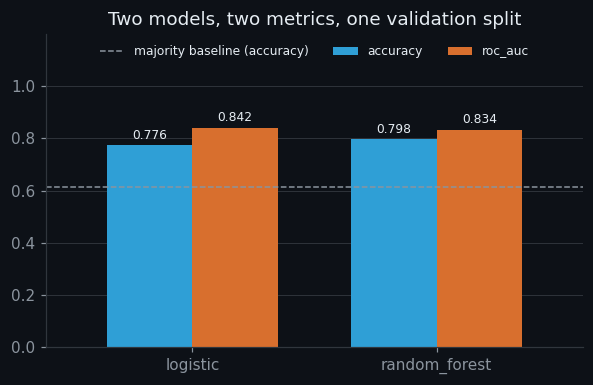

In [10]:
titanic = pd.read_csv(DATA / "titanic_dataset.csv")

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
t_num = ["Age", "SibSp", "Parch", "Fare"]
t_cat = ["Pclass", "Sex", "Embarked"]
X_t = titanic[features]
y_t = titanic["Survived"]

Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)
baseline = 1 - yt_valid.mean()
print("majority-class baseline accuracy:", round(baseline, 3))

scores = {}
fitted_t = {}
for name, estimator in {
    "logistic": LogisticRegression(max_iter=1000),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                            random_state=42),
}.items():
    pipe = Pipeline([("preprocess", make_preprocess(t_num, t_cat)), ("model", estimator)])
    pipe.fit(Xt_train, yt_train)
    fitted_t[name] = pipe
    scores[name] = {"accuracy": accuracy_score(yt_valid, pipe.predict(Xt_valid)),
                    "roc_auc": roc_auc_score(yt_valid, pipe.predict_proba(Xt_valid)[:, 1])}
    print(f"{name:14s} accuracy={scores[name]['accuracy']:.3f} "
          f"roc_auc={scores[name]['roc_auc']:.3f}")
summary["titanic_part_c"] = pd.DataFrame(scores).round(4).to_dict()
summary["titanic_baseline_accuracy"] = round(float(baseline), 4)

# The same logistic model, three decision rules (the table in the notes).
prob_t = fitted_t["logistic"].predict_proba(Xt_valid)[:, 1]
for threshold in [0.30, 0.50, 0.70]:
    pred_t = (prob_t >= threshold).astype(int)
    print(f"threshold {threshold:.2f}: precision={precision_score(yt_valid, pred_t):.2f} "
          f"recall={recall_score(yt_valid, pred_t):.2f}")

ax = pd.DataFrame(scores).T.plot.bar(figsize=(5.5, 3.6), rot=0, width=0.7)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=2, color=INK, fontsize=8)
ax.axhline(baseline, linestyle="--", color=MUTED, linewidth=1, label="majority baseline (accuracy)")
ax.set_ylim(0, 1.2)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_title("Two models, two metrics, one validation split")
ax.legend(loc="upper center", ncol=3, fontsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_plot("titanic_baselines.png")

**Observations.** Both models beat the majority baseline of 0.614 accuracy, but they disagree
on which one is better. The random forest wins on accuracy (0.798 against 0.776) and logistic
regression wins on ROC AUC (0.842 against 0.834). Gaps of 0.01 to 0.02 on 223 passengers are
too small to call from one split, which is what the cross-validation in Part D is for.

The threshold moves the trade-off without touching the model. With the same logistic
probabilities, a 0.30 threshold finds 81% of survivors at 64% precision, and 0.70 raises
precision to 90% while recall drops to 50%.

### Breast cancer: probabilities, confusion matrices, ROC and PR

30 tumour measurements per row; predict malignant (`M`, the positive class) against benign.
The histogram shows the predicted probabilities by true class, and a threshold is a vertical
line through it.

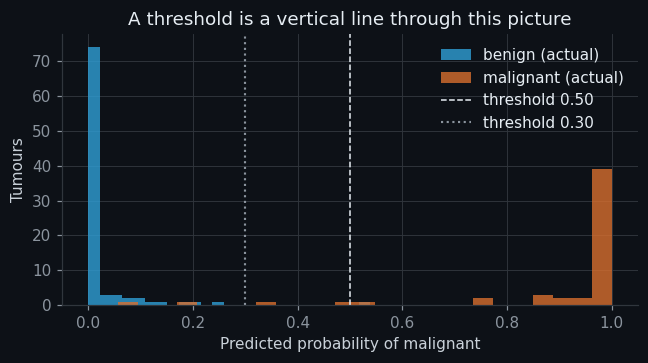

In [11]:
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

X_c = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")
y_c = (cancer["diagnosis"] == "M").astype(int)

Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
    X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)

cancer_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])
cancer_model.fit(Xc_train, yc_train)
prob = cancer_model.predict_proba(Xc_valid)[:, 1]

plt.figure(figsize=(6, 3.4))
plt.hist(prob[yc_valid == 0], bins=25, alpha=0.8, label="benign (actual)")
plt.hist(prob[yc_valid == 1], bins=25, alpha=0.8, label="malignant (actual)")
plt.axvline(0.50, color=INK, linestyle="--", linewidth=1, label="threshold 0.50")
plt.axvline(0.30, color=MUTED, linestyle=":", linewidth=1.4, label="threshold 0.30")
plt.xlabel("Predicted probability of malignant")
plt.ylabel("Tumours")
plt.title("A threshold is a vertical line through this picture")
plt.legend(loc="upper right")
plt.tight_layout()
save_plot("cancer_probabilities.png")

In a confusion matrix the rows are the truth and the columns are the decision. Precision is
the share of malignant alerts that are right; recall is the share of malignant tumours the
model catches. Lowering the threshold only adds alerts, so recall cannot go down.


threshold = 0.50
[[89  1]
 [ 4 49]]
              precision    recall  f1-score   support

           0      0.957     0.989     0.973        90
           1      0.980     0.925     0.951        53

    accuracy                          0.965       143
   macro avg      0.968     0.957     0.962       143
weighted avg      0.966     0.965     0.965       143


threshold = 0.30
[[89  1]
 [ 2 51]]
              precision    recall  f1-score   support

           0      0.978     0.989     0.983        90
           1      0.981     0.962     0.971        53

    accuracy                          0.979       143
   macro avg      0.979     0.976     0.977       143
weighted avg      0.979     0.979     0.979       143



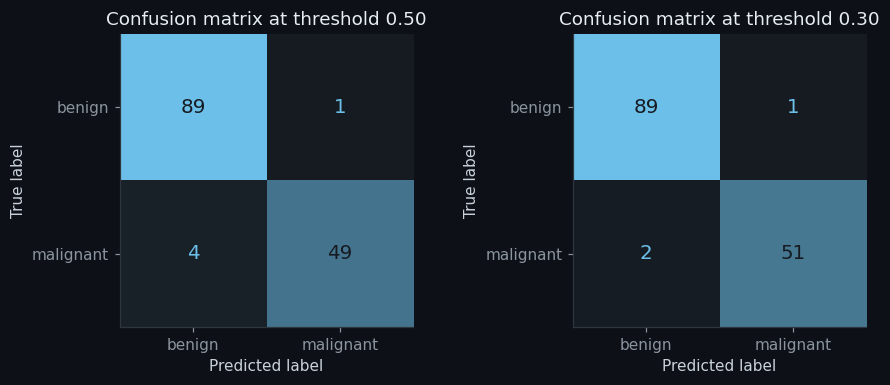

In [12]:
cancer_thresholds = []
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
for ax, threshold in zip(axes, [0.50, 0.30]):
    pred = (prob >= threshold).astype(int)
    print(f"\nthreshold = {threshold:.2f}")
    print(confusion_matrix(yc_valid, pred))
    print(classification_report(yc_valid, pred, digits=3))
    ConfusionMatrixDisplay.from_predictions(yc_valid, pred, display_labels=["benign", "malignant"],
                                            cmap=HEAT, colorbar=False, ax=ax, text_kw={"fontsize": 13})
    ax.set_title(f"Confusion matrix at threshold {threshold:.2f}")
    ax.grid(False)
    tn, fp, fn, tp = (int(v) for v in confusion_matrix(yc_valid, pred).ravel())
    cancer_thresholds.append({"threshold": threshold, "tn": tn, "fp": fp, "fn": fn, "tp": tp,
                              "precision": round(tp / (tp + fp), 4), "recall": round(tp / (tp + fn), 4)})
plt.tight_layout()
save_plot("cancer_confusion_matrices.png")
pd.DataFrame(cancer_thresholds).to_csv(RESULTS / "cancer_thresholds.csv", index=False)
summary["cancer_thresholds"] = cancer_thresholds

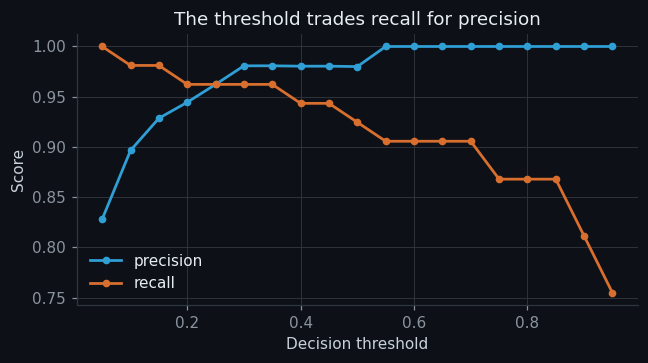

In [13]:
thresholds = np.linspace(0.05, 0.95, 19)
precisions = [precision_score(yc_valid, (prob >= t).astype(int), zero_division=0)
              for t in thresholds]
recalls = [recall_score(yc_valid, (prob >= t).astype(int)) for t in thresholds]

plt.figure(figsize=(6, 3.4))
plt.plot(thresholds, precisions, marker="o", markersize=4, label="precision")
plt.plot(thresholds, recalls, marker="o", markersize=4, label="recall")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("The threshold trades recall for precision")
plt.legend(loc="lower left")
plt.tight_layout()
save_plot("cancer_threshold_tradeoff.png")

**Observations.** Most tumours get a probability close to 0 or 1, and the few in between
decide what the threshold changes. At 0.50 the model misses 4 of the 53 malignant tumours and
raises 1 false alarm among the 90 benign ones. At 0.30 it misses 2 and still raises only 1
false alarm, so recall goes from 0.925 to 0.962 while precision stays at 0.98.

ROC AUC measures how well the model ranks malignant above benign across every threshold.
Average precision summarizes the precision-recall curve, which focuses on finding the
positives.

ROC AUC: 0.996
PR AUC: 0.994


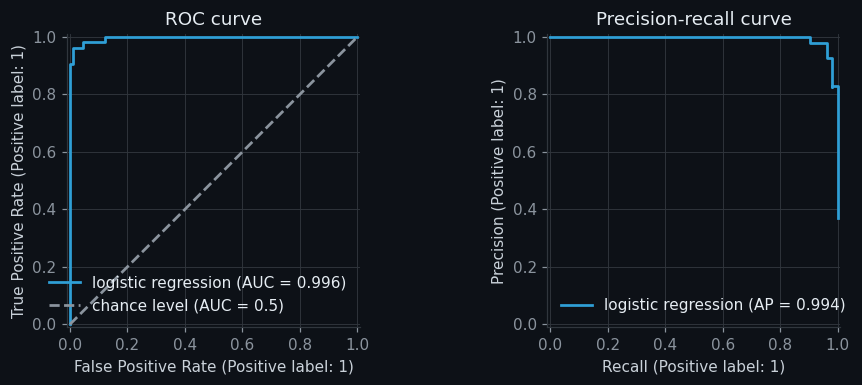

In [14]:
print("ROC AUC:", round(roc_auc_score(yc_valid, prob), 3))
print("PR AUC:", round(average_precision_score(yc_valid, prob), 3))
summary["cancer"] = {"roc_auc": round(roc_auc_score(yc_valid, prob), 4),
                     "average_precision": round(average_precision_score(yc_valid, prob), 4)}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
RocCurveDisplay.from_predictions(yc_valid, prob, ax=axes[0], plot_chance_level=True,
                                 chance_level_kw={"color": MUTED, "linestyle": "--"})
axes[0].set_title("ROC curve")
# sklearn's own legend rounds to 2 decimals, which shows 0.996 as a perfect 1.00
axes[0].legend([f"logistic regression (AUC = {summary['cancer']['roc_auc']:.3f})",
                "chance level (AUC = 0.5)"], loc="lower right")
PrecisionRecallDisplay.from_predictions(yc_valid, prob, ax=axes[1])
axes[1].set_title("Precision-recall curve")
axes[1].legend([f"logistic regression (AP = {summary['cancer']['average_precision']:.3f})"],
               loc="lower left")
plt.tight_layout()
save_plot("cancer_roc_pr.png")

**Observations.** ROC AUC is 0.996 and average precision 0.994: the model ranks almost every
malignant tumour above every benign one. That is why moving the threshold from 0.50 to 0.30
changes the decision for only two tumours.

### Decision memo

**Choice: threshold 0.30.** A missed malignant tumour (false negative) can delay treatment,
while a false alarm leads to a follow-up test. Here a false negative costs much more than a
false positive.

On the 143 validation tumours, lowering the threshold from 0.50 to 0.30 moves two malignant
tumours from missed to caught: false negatives drop from 4 to 2 and true positives rise from
49 to 51. False positives stay at 1, so the extra caution costs nothing on this sample.
Recall rises from 0.925 to 0.962 and precision stays at 0.98.

Two caveats. 143 tumours is a small sample, and I picked the threshold on the same rows I
report it on, so these numbers flatter the choice a little. Before relying on it, I would
confirm the threshold on fresh data and agree the error costs with clinicians.

## Part D: Tune with cross-validation, then test once

Five-fold stratified cross-validation on the training rows picks `C` and `class_weight`, and
`GridSearchCV` refits the winner on all the training rows.

As in the handout, this split uses the same seed and size as Part C, so the 223 test rows
here are the passengers Part C used for validation. The tuning below never sees them, but
they are not completely fresh: Part C already scored two models on them. A stricter setup
would hold the test rows out before Part C.

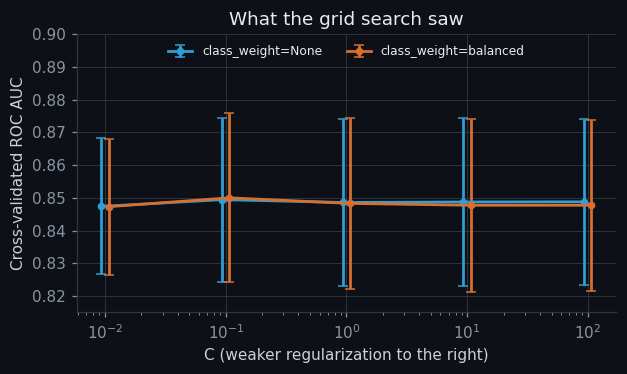

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_t, y_t, test_size=0.25, random_state=42, stratify=y_t
)

search = GridSearchCV(
    Pipeline([("preprocess", make_preprocess(t_num, t_cat)),
              ("model", LogisticRegression(max_iter=2000))]),
    param_grid={
        "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
)
search.fit(X_train, y_train)

cv_table = pd.DataFrame(search.cv_results_)
cv_table["class_weight"] = cv_table["param_model__class_weight"].map(
    lambda w: "balanced" if w == "balanced" else "None")
cv_table[["param_model__C", "class_weight", "mean_test_score", "std_test_score",
          "rank_test_score"]].to_csv(RESULTS / "titanic_cv_results.csv", index=False)

plt.figure(figsize=(5.8, 3.5))
nudge = {"None": 0.93, "balanced": 1.07}  # side by side, so both error bars stay visible
for weight, group in cv_table.groupby("class_weight"):
    plt.errorbar(group["param_model__C"].astype(float) * nudge[weight], group["mean_test_score"],
                 yerr=group["std_test_score"], marker="o", markersize=4, capsize=3,
                 label=f"class_weight={weight}")
plt.xscale("log")
plt.xlabel("C (weaker regularization to the right)")
plt.ylabel("Cross-validated ROC AUC")
plt.title("What the grid search saw")
plt.ylim(0.815, 0.9)
plt.legend(loc="upper center", ncol=2, fontsize=8)
plt.tight_layout()
save_plot("titanic_cross_validation.png")

Only now is the test set touched, once.

In [16]:
test_prob = search.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_prob)

print("best parameters:", search.best_params_)
print("cross-validated ROC AUC:", round(search.best_score_, 3))
print("final test ROC AUC:", round(test_auc, 3))
summary["titanic_final"] = {"best_parameters": search.best_params_,
                            "cv_roc_auc": round(float(search.best_score_), 4),
                            "test_roc_auc": round(float(test_auc), 4)}

best parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
cross-validated ROC AUC: 0.85
final test ROC AUC: 0.837


**Observations.** The best setting is `C=0.1` with balanced class weights, at a mean
cross-validated ROC AUC of 0.850. All ten settings score between 0.847 and 0.850, while each
one moves by 0.021 to 0.026 from fold to fold, so the folds disagree more than the settings
do. Any of them would do about as well. The single test evaluation gives 0.837, close to the
cross-validation estimate.

## Part E: Save the models and use them

`joblib.dump` saves the preprocessing and the classifier together as one pipeline, and a JSON
card records the inputs and the evaluation.

In [17]:
final_model = search.best_estimator_
model_path = MODELS / "titanic_survival.joblib"
joblib.dump(final_model, model_path)

card = {
    "task": "predict Titanic survival (1 = survived)",
    "features": features,
    "model": "logistic regression pipeline",
    "best_parameters": search.best_params_,
    "training_rows": int(len(X_train)),
    "cross_validated_roc_auc": round(float(search.best_score_), 3),
    "final_test_roc_auc": round(float(test_auc), 3),
    "decision_threshold": 0.5,
    "scikit_learn_version": sklearn.__version__,
}
(MODELS / "titanic_survival_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")
size_kb = model_path.stat().st_size / 1024
print(f"saved: {model_path.name} ({size_kb:.1f} KB) and titanic_survival_card.json")

saved: titanic_survival.joblib (4.5 KB) and titanic_survival_card.json


Load the pipeline and predict new rows with matching columns, without retraining. Then the
same for two insurance customers who differ only in `smoker`.

In [18]:
loaded = joblib.load(model_path)
new_passengers = pd.DataFrame([
    {"Pclass": 1, "Sex": "female", "Age": 29, "SibSp": 0, "Parch": 0, "Fare": 80.0, "Embarked": "C"},
    {"Pclass": 3, "Sex": "male",   "Age": 40, "SibSp": 0, "Parch": 0, "Fare":  7.9, "Embarked": "S"},
])
new_passengers["survival_probability"] = loaded.predict_proba(new_passengers)[:, 1].round(3)
display(new_passengers)

joblib.dump(fitted["linear regression"], MODELS / "insurance_charges.joblib")
pricing = joblib.load(MODELS / "insurance_charges.joblib")
new_customer = pd.DataFrame([
    {"age": 35, "sex": "female", "bmi": 27.5, "children": 2, "smoker": "no", "region": "southeast"},
    {"age": 35, "sex": "female", "bmi": 27.5, "children": 2, "smoker": "yes", "region": "southeast"},
])
new_customer["predicted_charges"] = pricing.predict(new_customer).round(0)
display(new_customer)

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,survival_probability
0,1,female,29,0,0,80.0,C,0.942
1,3,male,40,0,0,7.9,S,0.141


,age,sex,bmi,children,smoker,region,predicted_charges
0,35,female,27.5,2,no,southeast,6526.0
1,35,female,27.5,2,yes,southeast,30177.0


Run the saved passenger model from the terminal. `predict_passenger.py` sits next to this
notebook and only loads the two files saved above.

In [19]:
# Same as typing in a terminal: python predict_passenger.py --pclass 2 --sex female --age 30 --fare 20
!"{sys.executable}" predict_passenger.py --pclass 2 --sex female --age 30 --fare 20

survival probability: 0.805  ->  survived
(model: logistic regression pipeline, test ROC AUC 0.837)


**Observations.** The reloaded pipeline gives the first-class woman a survival probability of
0.942 and the third-class man 0.141, with no retraining. The two insurance customers differ
only in `smoker`, and the predicted charge jumps from $6,526 to $30,177, the same $23,651 gap
as the OLS coefficients. From the terminal, a 30-year-old woman in second class who paid a
fare of 20 gets 0.805, above the 0.5 threshold, so the model predicts that she survived.

## Try it yourself: heart disease

The Part C workflow on `heart_failure_dataset.csv` with the label `HeartDisease`.
`select_dtypes` builds the column lists, `make_preprocess` does the preprocessing, and the
report covers accuracy, ROC AUC and the confusion matrix at threshold 0.5.

numeric: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
categorical: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

accuracy: 0.883
ROC AUC: 0.932
[[ 86  17]
 [ 10 117]]
              precision    recall  f1-score   support

           0      0.896     0.835     0.864       103
           1      0.873     0.921     0.897       127

    accuracy                          0.883       230
   macro avg      0.884     0.878     0.880       230
weighted avg      0.883     0.883     0.882       230



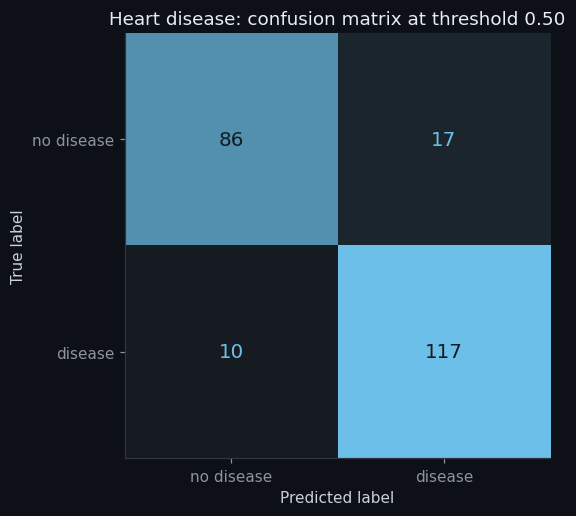

In [20]:
heart = pd.read_csv(DATA / "heart_failure_dataset.csv")
X_hd = heart.drop(columns="HeartDisease")
y_hd = heart["HeartDisease"]
hd_num = X_hd.select_dtypes(include="number").columns.tolist()
hd_cat = X_hd.select_dtypes(exclude="number").columns.tolist()
print("numeric:", hd_num)
print("categorical:", hd_cat)

Xhd_train, Xhd_valid, yhd_train, yhd_valid = train_test_split(
    X_hd, y_hd, test_size=0.25, random_state=42, stratify=y_hd
)
heart_model = Pipeline([
    ("preprocess", make_preprocess(hd_num, hd_cat)),
    ("model", LogisticRegression(max_iter=1000)),
])
heart_model.fit(Xhd_train, yhd_train)
heart_prob = heart_model.predict_proba(Xhd_valid)[:, 1]
heart_pred = (heart_prob >= 0.5).astype(int)

print("\naccuracy:", round(accuracy_score(yhd_valid, heart_pred), 3))
print("ROC AUC:", round(roc_auc_score(yhd_valid, heart_prob), 3))
print(confusion_matrix(yhd_valid, heart_pred))
print(classification_report(yhd_valid, heart_pred, digits=3))
summary["heart"] = {"accuracy": round(accuracy_score(yhd_valid, heart_pred), 4),
                    "roc_auc": round(roc_auc_score(yhd_valid, heart_prob), 4),
                    "confusion_matrix": confusion_matrix(yhd_valid, heart_pred).tolist()}

ConfusionMatrixDisplay.from_predictions(yhd_valid, heart_pred, display_labels=["no disease", "disease"],
                                        cmap=HEAT, colorbar=False, text_kw={"fontsize": 13})
plt.title("Heart disease: confusion matrix at threshold 0.50")
plt.grid(False)
plt.tight_layout()
save_plot("heart_confusion_matrix.png")

(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8");

**Observations.** Accuracy 0.883 and ROC AUC 0.932 on 230 validation patients. At threshold
0.5 the model misses 10 of the 127 patients with heart disease and raises 17 false alarms
among the 103 without. As with the tumours, a lower threshold would catch more patients at
the cost of more false alarms. One catch with building the column lists from dtypes:
`FastingBS` is a 0/1 flag stored as a number, so it gets scaled like a measurement instead of
one-hot encoded. For a yes/no flag that makes little difference, but a category stored as
number codes (1 to 4, say) would need to go into the categorical list by hand.

## Check your understanding

**1. Why is logistic regression called a linear classifier even though it outputs a nonlinear sigmoid probability?**

The model computes a linear score, z = w·x + b, and only then passes it through the sigmoid.
The sigmoid is increasing, so "probability ≥ 0.5" is the same as "z ≥ 0", and any other
threshold is "z ≥ some constant". Every decision boundary is therefore a flat hyperplane in
feature space. The sigmoid changes how scores map to probabilities and leaves the boundary
straight.

**2. Why should the probability model and the operational classification threshold be treated as separate objects?**

They answer different questions. The model estimates how likely each case is; the threshold
decides what to do about it, and that depends on things outside the data: what a miss costs,
what a false alarm costs, how many follow-ups a clinic can handle. Keeping them separate lets
you change the decision rule without retraining, as in Part C, where the same tumour
probabilities gave two different confusion matrices. Choose the threshold on validation data
and confirm it on held-out data.

**3. What changes when binary logistic regression is extended to a multiclass softmax model?**

Each class gets its own weight vector and linear score. Softmax turns the K scores into K
probabilities that sum to 1, and the prediction is usually the class with the highest one.
Training minimizes multiclass cross-entropy instead of binary log loss. A single
positive-class threshold no longer applies, so evaluation moves to per-class precision and
recall, a K × K confusion matrix, or averaged metrics.

## Chapter 4: Check your understanding

**1. What feedback signal separates supervised, unsupervised, limited-label, and reinforcement-learning problems?**

Supervised learning has a label for every example. Unsupervised learning has no labels and
looks for structure in the features alone. Limited-label learning has labels for only some
examples and uses the unlabelled ones too, or asks for the most useful labels. Reinforcement
learning gets rewards after actions instead of labels.

**2. Why can two learning settings share data preparation and monitoring practices while requiring different fitting objectives?**

Both need a trustworthy table, a split that matches how the model will be used, and
monitoring once it runs. The fitting objective comes from the feedback: prediction loss when
labels exist; compactness, reconstruction or density when they do not; expected long-term
reward for an agent.

**3. What is the difference between reducing a training objective and demonstrating generalization?**

A lower training loss shows that the model fits the examples it has already seen.
Generalization means good performance on new data, and the only way to show it is to evaluate
on data the model never trained on, with a split that matches real use: future dates for the
bike forecast, untouched test rows for Titanic.